# A18 堵车或故障时应该预留多少备用能力？

你要搜索车辆备用数和触发备用的阈值。每个策略都要模拟很多场景，所以把仿真当作黑箱，比较随机搜索与Ax贝叶斯优化。

先修：基础课 Python、NumPy、实验评价

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


### 1. 定义可行动的策略参数
reserve 是预先购买的备用车数量，threshold 是积压触发阈值。假设每天订单批次已到齐、故障已检查后才决定是否启用备用，这是观察后的补救动作；不能把完整日需求提前用于事前购车。模型只包含车队总容量，不能推断真实道路最优路线。训练与复评种子分开。

In [2]:
import numpy as np
import pandas as pd
import torch
torch.set_num_threads(2)

def fleet_cost(reserve, threshold, seeds):
    losses = []
    late_rates = []
    for seed in seeds:
        rng = np.random.default_rng(int(seed))
        demand = rng.poisson(95, 30)
        failures = rng.binomial(10, 0.08, 30)
        base_capacity = (10 - failures) * 10
        deploy = np.where(demand - base_capacity > threshold, reserve, 0)
        late = np.maximum(0, demand - base_capacity - 10 * deploy)
        losses.append(float(np.mean(8 * late + reserve * 4 + deploy * 2)))
        late_rates.append(float(late.sum() / demand.sum()))
    return (float(np.mean(losses)), float(np.mean(late_rates)))
train_seeds = list(range(180, 190))
test_seeds = list(range(500, 550))
budget = 10
assert fleet_cost(2, 8, [1]) == fleet_cost(2, 8, [1])

### 2. 建立同预算随机搜索
每次目标调用使用相同的10个校准情景。记录函数调用数；不能给某方法多十倍试验再宣称它更聪明。

In [3]:
rng = np.random.default_rng(18)
random_trials = []
for i in range(budget):
    parameters = {'reserve': int(rng.integers(0, 7)), 'threshold': int(rng.integers(0, 26))}
    value, _ = fleet_cost(**parameters, seeds=train_seeds)
    random_trials.append(dict(trial=i, **parameters, cost=value))
random_best = min(random_trials, key=lambda row: row['cost'])

### 3. 用Ax逐步选试验
Ax先用空间填充试验学习，再让代理模型建议候选。这里固定前4次Sobol、后6次贝叶斯选点，防止短教程全部停留在初始化。代理模型也有成本，不能保证十次试验就找到全局最优。

In [4]:
from ax.service.ax_client import AxClient, ObjectiveProperties
from ax.modelbridge.generation_strategy import GenerationStrategy, GenerationStep
from ax.modelbridge.registry import Models
strategy = GenerationStrategy(steps=[GenerationStep(model=Models.SOBOL, num_trials=4, model_kwargs={'seed': 18}), GenerationStep(model=Models.BOTORCH_MODULAR, num_trials=-1, model_gen_kwargs={'model_gen_options': {'optimizer_kwargs': {'num_restarts': 2, 'raw_samples': 32}}})])
client = AxClient(generation_strategy=strategy, random_seed=18, verbose_logging=False)
client.create_experiment(name='fleet_reserve', parameters=[{'name': 'reserve', 'type': 'range', 'bounds': [0, 6], 'value_type': 'int'}, {'name': 'threshold', 'type': 'range', 'bounds': [0, 25], 'value_type': 'int'}], objectives={'cost': ObjectiveProperties(minimize=True)})
ax_trials = []
for i in range(budget):
    parameters, trial_index = client.get_next_trial()
    value, _ = fleet_cost(**parameters, seeds=train_seeds)
    client.complete_trial(trial_index=trial_index, raw_data={'cost': (value, 0.0)})
    ax_trials.append(dict(trial=i, **parameters, cost=value))
ax_best = min(ax_trials, key=lambda row: row['cost'])

[WARNING 10-20 15:45:17] ax.service.ax_client: Random seed set to 18. Note that this setting only affects the Sobol quasi-random generator and BoTorch-powered Bayesian optimization models. For the latter models, setting random seed to the same number for two optimizations will make the generated trials similar, but not exactly the same, and over time the trials will diverge more.


[INFO 10-20 15:45:17] ax.service.utils.instantiation: Created search space: SearchSpace(parameters=[RangeParameter(name='reserve', parameter_type=INT, range=[0, 6]), RangeParameter(name='threshold', parameter_type=INT, range=[0, 25])], parameter_constraints=[]).


[课程目录]\.venv\Lib\site-packages\ax\modelbridge\cross_validation.py:439: UserWarning: Encountered exception in computing model fit quality: RandomModelBridge does not support prediction.
  warn("Encountered exception in computing model fit quality: " + str(e))
[课程目录]\.venv\Lib\site-packages\ax\modelbridge\cross_validation.py:439: UserWarning: Encountered exception in computing model fit quality: RandomModelBridge does not support prediction.
  warn("Encountered exception in computing model fit quality: " + str(e))
[课程目录]\.venv\Lib\site-packages\ax\modelbridge\cross_validation.py:439: UserWarning: Encountered exception in computing model fit quality: RandomModelBridge does not support prediction.
  warn("Encountered exception in computing model fit quality: " + str(e))
[课程目录]\.venv\Lib\site-packages\ax\modelbridge\cross_validation.py:439: UserWarning: Encountered exception in computing model fit quality: RandomModelBridge does not support prediction.
  warn("Encountered exception in compu

### 4. 只在选型之后独立复评
同样的最终情景评价两个已选策略，再记录无备用基线。学习目标是形成可靠比较，不能强求贝叶斯优化一定赢。图展示已消耗预算下的历史最好值。

In [5]:
evaluation = []
for name, row in [('random', random_best), ('ax', ax_best), ('no_reserve', {'reserve': 0, 'threshold': 0})]:
    value, late = fleet_cost(row['reserve'], row['threshold'], test_seeds)
    evaluation.append({'method': name, 'reserve': int(row['reserve']), 'threshold': int(row['threshold']), 'test_cost': value, 'late_rate': late})
pd.DataFrame(evaluation).to_csv(OUT_DIR / 'independent_evaluation.csv', index=False)
for name, trials in [('random', random_trials), ('Ax', ax_trials)]:
    plt.plot(range(1, budget + 1), np.minimum.accumulate([row['cost'] for row in trials]), marker='o', label=name)
plt.xlabel('已用仿真目标调用次数')
plt.ylabel('当前最好校准损失')
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'search.png')
plt.close()
metrics = {'calls_per_method': budget, 'initial_sobol_trials': 4, 'bayesian_trials': 6, 'independent_results': evaluation}
recommendation = '两个搜索方法各使用10次目标调用，候选通过独立情景复评。请按 independent_evaluation.csv 比较损失和延误率；本次小预算实验不支持宣布某搜索方法普遍更优。'

### 保存可核验的证据
把指标写入 JSON，并用本次输出形成有条件的建议。json.dumps 把字典变成文本；不会替你判断方案是否适合现实。

In [6]:
import json
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT_DIR / '决策建议.md').write_text('# 本次计算的决策建议\n\n' + recommendation + '\n\n## 实际指标\n```json\n' + json.dumps(metrics, ensure_ascii=False, indent=2) + '\n```\n\n这些结论只适用于本例显式假设；目标权重和风险偏好由人决定。', encoding='utf-8')
print(metrics)

{'calls_per_method': 10, 'initial_sobol_trials': 4, 'bayesian_trials': 6, 'independent_results': [{'method': 'random', 'reserve': 2, 'threshold': 2, 'test_cost': 16.656000000000002, 'late_rate': 0.008869021362450746}, {'method': 'ax', 'reserve': 3, 'threshold': 0, 'test_cost': 16.61733333333333, 'late_rate': 0.0017981809753917343}, {'method': 'no_reserve', 'reserve': 0, 'threshold': 0, 'test_cost': 51.845333333333336, 'late_rate': 0.06845635996695291}]}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

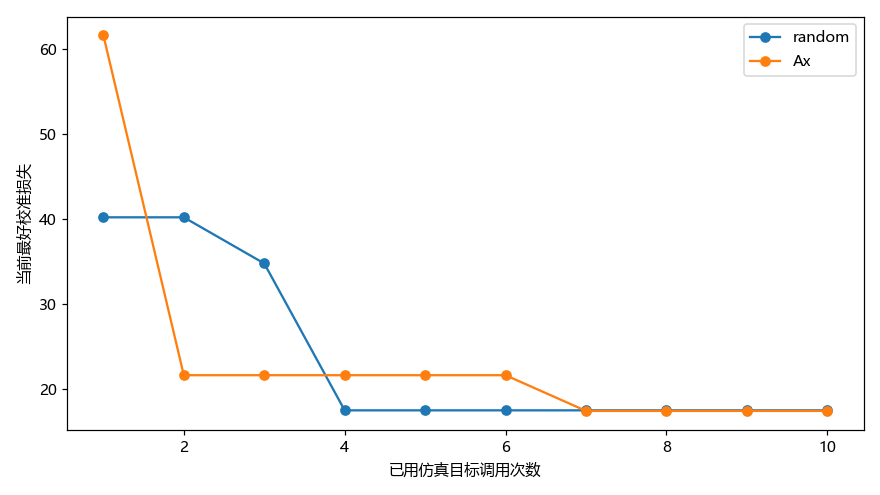

In [7]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
Ax有拟合开销，简单小空间枚举可能更好。固定校准情景只减少比较噪声，不代表现实确定。须将搜索成本与执行策略成本分开。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。